# Santander Customer Transaction Prediction

Решение соревнования [Santander Customer Transaction Prediction](https://www.kaggle.com/c/santander-customer-transaction-prediction) (Kaggle).

**Задача:** бинарная классификация, предсказать вероятность того, что клиент совершит транзакцию.
**Метрика:** ROC-AUC.
**Итоговый результат:** Public 0.89800 / Private 0.89526 (см. README.md).

Структура ноутбука:
1. Загрузка данных и EDA
2. Train/test split и препроцессинг
3. Feature Engineering (базовый набор)
4. Baseline-модели
5. Подбор гиперпараметров
6. Feature Engineering (продвинутый: real/synthetic split теста, ранги, полиномы)
7. Модели на расширенных признаках
8. Ансамбль (взвешенный блендинг + стекинг)
9. Генерация submission

## 1. Загрузка данных и настройка окружения

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

RANDOM_STATE = 42

In [2]:
import pandas as pd
import numpy as np

train = pd.read_csv("C:/Users/User/Downloads/santander-customer-transaction-prediction/train.csv")
test = pd.read_csv("C:/Users/User/Downloads/santander-customer-transaction-prediction/test.csv")

# Отделяем признаки и таргет
X = train.drop(columns=['ID_code', 'target'])
y = train['target']

print(X.shape, y.shape)

(200000, 200) (200000,)


## 2. Разведочный анализ данных (EDA)

Ключевые наблюдения:
- Пропусков и дубликатов нет
- Сильный дисбаланс классов (~90% / ~10%)
- Признаки практически не коррелируют друг с другом

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), str(1)
memory usage: 308.2 MB
Пропуски: 0
Дубликаты: 0
target
0    0.89951
1    0.10049
Name: proportion, dtype: float64


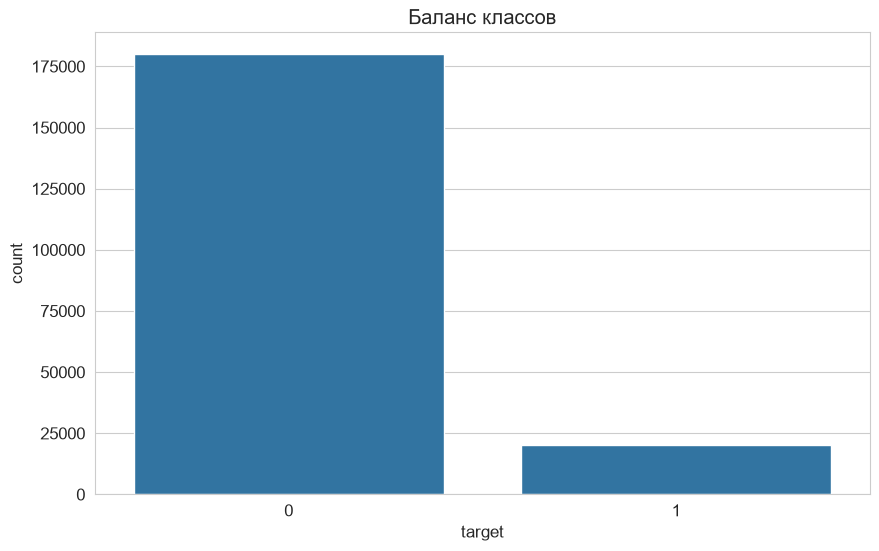

In [3]:
train.info()
train.describe()
print('Пропуски:', train.isnull().sum().sum())
print('Дубликаты:', train.duplicated().sum())
print(train['target'].value_counts(normalize=True))
sns.countplot(x='target', data=train)
plt.title('Баланс классов')
plt.show()

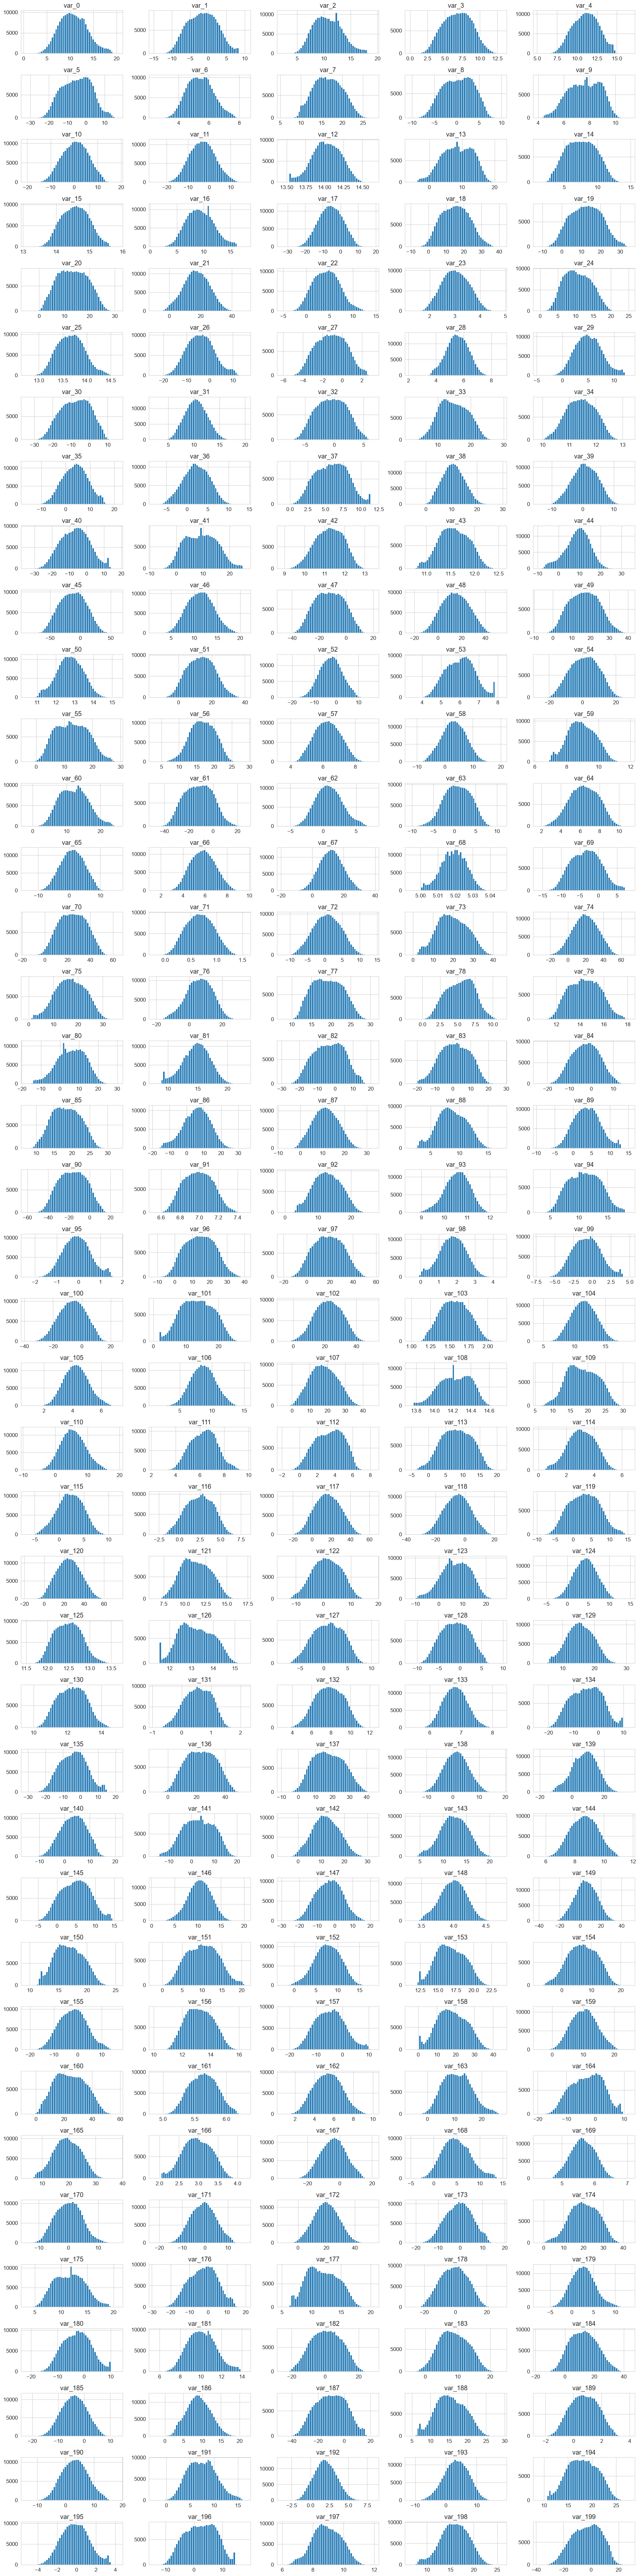

In [4]:
features = [c for c in train.columns if c.startswith('var_')]

train[features].hist(
    figsize=(20, 80),
    bins=50,
    layout=(40, 5)
)
plt.tight_layout()
plt.show()

In [5]:
outliers = {}

for col in features:
    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers[col] = ((train[col] < lower) | (train[col] > upper)).sum()

outliers = pd.Series(outliers).sort_values(ascending=False)
print(outliers.head(20))

var_179    1509
var_44     1208
var_93      889
var_146     804
var_192     733
var_31      637
var_133     589
var_105     572
var_38      502
var_124     498
var_110     470
var_67      465
var_193     461
var_186     446
var_62      432
var_170     413
var_58      401
var_172     397
var_106     397
var_149     383
dtype: int64


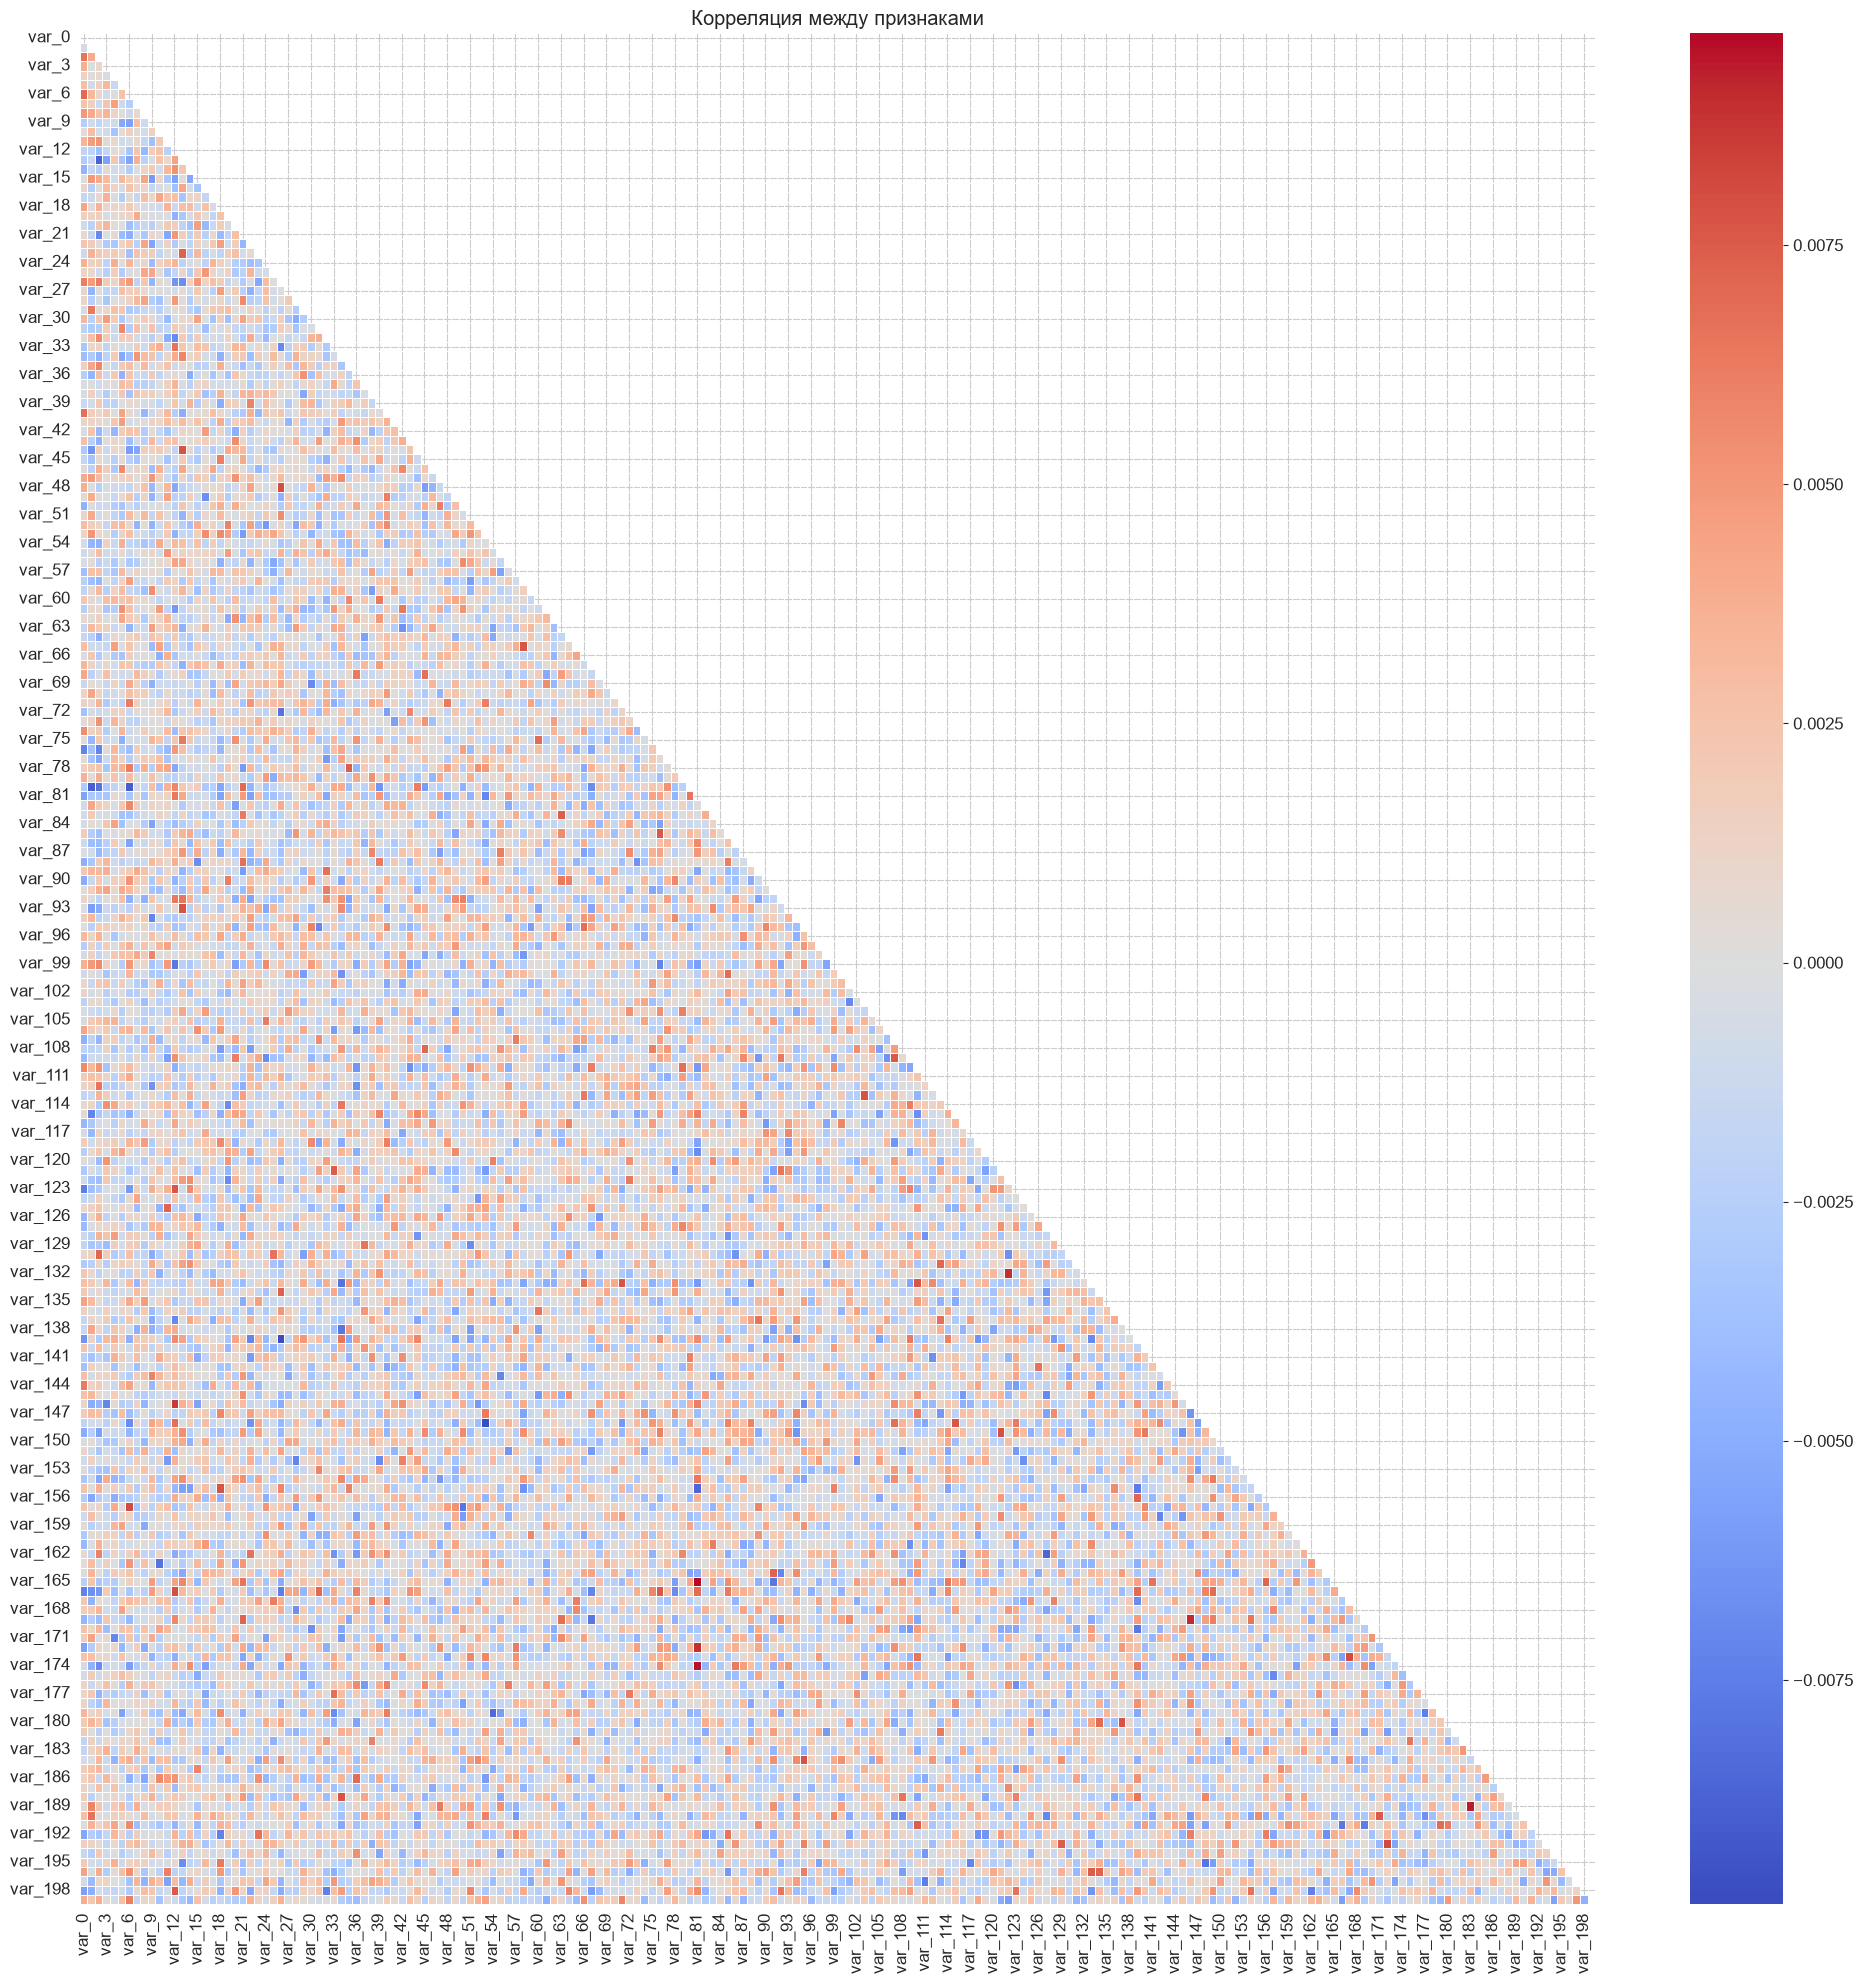

In [6]:
corr = train[features].corr()

plt.figure(figsize=(20, 20))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Корреляция между признаками')
plt.tight_layout()
plt.show()

По значениям шкалы видно, что корреляция между признаками практически отсутствует (|corr| < 0.01). Это исключает методы отбора признаков на основе линейной корреляции и смещает фокус на генерацию count/frequency-признаков и использование деревянных моделей.

## 3. Train/test split и препроцессинг

In [7]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, f1_score, roc_auc_score, ConfusionMatrixDisplay)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# Масштабирование — нужно для линейных/вероятностных моделей (Logistic Regression, Naive Bayes)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

## 4. Feature Engineering (базовый набор)

- **Row-статистики**: агрегаты по всем 200 признакам одной строки (sum, mean, std, min, max, median, skew, kurtosis)
- **Count-признаки**: частота каждого значения признака в train + test
- **is_unique / x_count**: производные от count-признаков

In [8]:
def add_row_stats(df, features):
    df = df.copy()
    df['row_sum'] = df[features].sum(axis=1)
    df['row_mean'] = df[features].mean(axis=1)
    df['row_std'] = df[features].std(axis=1)
    df['row_min'] = df[features].min(axis=1)
    df['row_max'] = df[features].max(axis=1)
    df['row_median'] = df[features].median(axis=1)
    df['row_skew'] = df[features].skew(axis=1)
    df['row_kurt'] = df[features].kurt(axis=1)
    return df

train_fe = add_row_stats(train, features)
test_fe = add_row_stats(test, features)
print(train_fe.shape, test_fe.shape)

(200000, 210) (200000, 209)


In [9]:
def add_count_features(train_df, test_df, features):
    train_df = train_df.copy()
    test_df = test_df.copy()
    combined = pd.concat([train_df[features], test_df[features]], axis=0)

    for col in features:
        value_counts = combined[col].value_counts()
        train_df[f'{col}_count'] = train_df[col].map(value_counts)
        test_df[f'{col}_count'] = test_df[col].map(value_counts)

    return train_df, test_df

train_fe, test_fe = add_count_features(train_fe, test_fe, features)
print(train_fe.shape, test_fe.shape)

(200000, 410) (200000, 409)


In [10]:
for col in features:
    train_fe[f'{col}_is_unique'] = (train_fe[f'{col}_count'] == 1).astype(int)
    test_fe[f'{col}_is_unique'] = (test_fe[f'{col}_count'] == 1).astype(int)

for col in features:
    train_fe[f'{col}_x_count'] = train_fe[col] * train_fe[f'{col}_count']
    test_fe[f'{col}_x_count'] = test_fe[col] * test_fe[f'{col}_count']

print(f'Итоговое число признаков: {train_fe.shape[1]}')

Итоговое число признаков: 810


**Освобождаем память:** сырой `train` (без FE) больше не нужен, тк вся необходимая информация уже перенесена в `train_fe`. `test` пока оставляем, тк понадобится в разделе 6 для определения настоящих и синтетических строк. (О наличии таких строк в датасете было выяснено из обсуждения на кегле)

In [11]:
import gc

del train
gc.collect()

913604

## 5. Baseline-модели

Пять разнородных моделей на сырых 200 признаках, без тюнинга - точка отсчёта для дальнейших итераций.
Метрика везде - ROC-AUC (метрика соревнования), кросс-валидация - `StratifiedKFold` (важно при сильном дисбалансе классов).

In [12]:
from sklearn.naive_bayes import GaussianNB
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

neg, pos = y_train.value_counts()
scale_pos_weight = neg / pos
print(f'scale_pos_weight: {scale_pos_weight:.2f}')

scale_pos_weight: 8.95


### 5.1 Logistic Regression

In [13]:
lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=RANDOM_STATE
)

lr_cv_scores = cross_val_score(lr, X_train_sc, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f'Logistic Regression CV ROC-AUC: {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})')

lr.fit(X_train_sc, y_train)
lr_pred_proba = lr.predict_proba(X_test_sc)[:, 1]
lr_pred = lr.predict(X_test_sc)

print(f'\nLogistic Regression Holdout ROC-AUC: {roc_auc_score(y_test, lr_pred_proba):.4f}')
print(f'F1-score: {f1_score(y_test, lr_pred):.4f}')

Logistic Regression CV ROC-AUC: 0.8590 (+/- 0.0031)

Logistic Regression Holdout ROC-AUC: 0.8599
F1-score: 0.4184


### 5.2 LightGBM (baseline)

In [14]:
lgbm_base = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)

lgbm_baseline_scores = cross_val_score(lgbm_base, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f'LightGBM baseline CV ROC-AUC: {lgbm_baseline_scores.mean():.4f} (+/- {lgbm_baseline_scores.std():.4f})')

LightGBM baseline CV ROC-AUC: 0.8814 (+/- 0.0029)


### 5.3 Naive Bayes

Неожиданно сильный baseline: раз признаки практически независимы (см. EDA), предпосылка метода близка к реальности.

In [15]:
nb = GaussianNB()

nb_cv_scores = cross_val_score(nb, X_train_sc, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f'Naive Bayes CV ROC-AUC: {nb_cv_scores.mean():.4f} (+/- {nb_cv_scores.std():.4f})')

nb.fit(X_train_sc, y_train)
nb_pred_proba = nb.predict_proba(X_test_sc)[:, 1]
nb_pred = nb.predict(X_test_sc)

print(f'\nNaive Bayes Holdout ROC-AUC: {roc_auc_score(y_test, nb_pred_proba):.4f}')
print(f'F1-score: {f1_score(y_test, nb_pred):.4f}')

Naive Bayes CV ROC-AUC: 0.8882 (+/- 0.0021)

Naive Bayes Holdout ROC-AUC: 0.8882
F1-score: 0.4662


### 5.4 CatBoost (baseline)

In [16]:
cat_base = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    verbose=0,
    thread_count=-1
)

cat_baseline_scores = cross_val_score(cat_base, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=1)
print(f'CatBoost baseline CV ROC-AUC: {cat_baseline_scores.mean():.4f} (+/- {cat_baseline_scores.std():.4f})')

CatBoost baseline CV ROC-AUC: 0.8752 (+/- 0.0036)


### 5.5 XGBoost (baseline)

In [17]:
xgb_base = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric='auc'
)

xgb_baseline_scores = cross_val_score(xgb_base, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f'XGBoost baseline CV ROC-AUC: {xgb_baseline_scores.mean():.4f} (+/- {xgb_baseline_scores.std():.4f})')

XGBoost baseline CV ROC-AUC: 0.8677 (+/- 0.0034)


## 6. Подбор гиперпараметров

`RandomizedSearchCV` по каждому из трёх бустингов.

### 6.1 LightGBM

In [18]:
lgbm = LGBMClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=-1
)

lgbm_param_grid = {
    'n_estimators': [500, 800, 1000, 1500],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'num_leaves': [7, 10, 15, 31],
    'max_depth': [-1, 5, 7, 10],
    'min_child_samples': [5, 10, 20, 50],
    'subsample': [0.6, 0.7, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [0, 0.1, 1]
}

lgbm_search = RandomizedSearchCV(
    estimator=lgbm, param_distributions=lgbm_param_grid, n_iter=30,
    scoring='roc_auc', cv=skf, random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
lgbm_search.fit(X_train, y_train)

print('Лучшие параметры LightGBM:', lgbm_search.best_params_)
print(f'Лучший CV ROC-AUC: {lgbm_search.best_score_:.4f}')

best_lgbm_params = lgbm_search.best_params_
lgbm_final = LGBMClassifier(**best_lgbm_params, scale_pos_weight=scale_pos_weight,
                             random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)

lgbm_cv_scores = cross_val_score(lgbm_final, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f'LightGBM (optimized) CV ROC-AUC: {lgbm_cv_scores.mean():.4f}')
print(f'Было (baseline): {lgbm_baseline_scores.mean():.4f}')

lgbm_final.fit(X_train, y_train)
lgbm_pred_proba = lgbm_final.predict_proba(X_test)[:, 1]
print(f'Holdout ROC-AUC: {roc_auc_score(y_test, lgbm_pred_proba):.4f}')

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Лучшие параметры LightGBM: {'subsample': 0.6, 'reg_lambda': 0, 'reg_alpha': 0, 'num_leaves': 7, 'n_estimators': 1500, 'min_child_samples': 20, 'max_depth': -1, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Лучший CV ROC-AUC: 0.8930
LightGBM (optimized) CV ROC-AUC: 0.8930
Было (baseline): 0.8814
Holdout ROC-AUC: 0.8934


### 6.2 CatBoost

In [19]:
cat = CatBoostClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    verbose=0,
    thread_count=1
)

cat_param_grid = {
    'iterations': [400, 500, 600, 800],
    'learning_rate': [0.08, 0.1, 0.12, 0.15],
    'depth': [4, 5, 6],
    'l2_leaf_reg': [7, 10, 15, 20],
    'min_data_in_leaf': [5, 10, 15, 20],
    'random_strength': [1, 2, 3, 4],
    'bagging_temperature': [1, 2, 3, 4]
}

cat_search = RandomizedSearchCV(
    estimator=cat, param_distributions=cat_param_grid, n_iter=15,
    scoring='roc_auc', cv=3, random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
cat_search.fit(X_train, y_train)

print('Лучшие параметры CatBoost:', cat_search.best_params_)
print(f'Лучший CV ROC-AUC: {cat_search.best_score_:.4f}')

best_cat_params = cat_search.best_params_
cat_final = CatBoostClassifier(**best_cat_params, scale_pos_weight=scale_pos_weight,
                                random_state=RANDOM_STATE, verbose=0, thread_count=-1)

cat_cv_scores = cross_val_score(cat_final, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=1)
print(f'CatBoost (optimized) CV ROC-AUC: {cat_cv_scores.mean():.4f}')
print(f'Было (baseline): {cat_baseline_scores.mean():.4f}')

cat_final.fit(X_train, y_train)
cat_pred_proba = cat_final.predict_proba(X_test)[:, 1]
print(f'Holdout ROC-AUC: {roc_auc_score(y_test, cat_pred_proba):.4f}')

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Лучшие параметры CatBoost: {'random_strength': 1, 'min_data_in_leaf': 20, 'learning_rate': 0.1, 'l2_leaf_reg': 10, 'iterations': 800, 'depth': 4, 'bagging_temperature': 1}
Лучший CV ROC-AUC: 0.8915
CatBoost (optimized) CV ROC-AUC: 0.8935
Было (baseline): 0.8752
Holdout ROC-AUC: 0.8931


### 6.3 XGBoost

In [20]:
xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=1,
    eval_metric='auc'
)

xgb_param_grid = {
    'n_estimators': [800, 1000, 1200, 1500],
    'learning_rate': [0.03, 0.05, 0.07],
    'max_depth': [3, 4, 5],
    'min_child_weight': [2, 3, 5],
    'subsample': [0.9, 1.0],
    'colsample_bytree': [0.9, 1.0],
    'gamma': [0, 0.05, 0.1],
    'reg_alpha': [0, 0.01, 0.05],
    'reg_lambda': [1, 1.5, 2]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb, param_distributions=xgb_param_grid, n_iter=15,
    scoring='roc_auc', cv=3, random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
xgb_search.fit(X_train, y_train)

print('Лучшие параметры XGBoost:', xgb_search.best_params_)
print(f'Лучший CV ROC-AUC: {xgb_search.best_score_:.4f}')

best_xgb_params = xgb_search.best_params_
xgb_final = XGBClassifier(**best_xgb_params, scale_pos_weight=scale_pos_weight,
                           random_state=RANDOM_STATE, n_jobs=-1, eval_metric='auc')

xgb_cv_scores = cross_val_score(xgb_final, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f'XGBoost (optimized) CV ROC-AUC: {xgb_cv_scores.mean():.4f}')
print(f'Было (baseline): {xgb_baseline_scores.mean():.4f}')

xgb_final.fit(X_train, y_train)
xgb_pred_proba = xgb_final.predict_proba(X_test)[:, 1]
print(f'Holdout ROC-AUC: {roc_auc_score(y_test, xgb_pred_proba):.4f}')

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Лучшие параметры XGBoost: {'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha': 0.05, 'n_estimators': 1500, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.07, 'gamma': 0, 'colsample_bytree': 1.0}
Лучший CV ROC-AUC: 0.8913
XGBoost (optimized) CV ROC-AUC: 0.8928
Было (baseline): 0.8677
Holdout ROC-AUC: 0.8934


### 6.4 Сводная таблица (после тюнинга, до продвинутого FE)

In [21]:
baseline_results = pd.DataFrame({
    'model': ['Logistic Regression', 'LightGBM (tuned)', 'Naive Bayes', 'XGBoost (tuned)', 'CatBoost (tuned)'],
    'cv_roc_auc_mean': [lr_cv_scores.mean(), lgbm_cv_scores.mean(), nb_cv_scores.mean(),
                        xgb_cv_scores.mean(), cat_cv_scores.mean()],
    'holdout_roc_auc': [
        roc_auc_score(y_test, lr_pred_proba), roc_auc_score(y_test, lgbm_pred_proba),
        roc_auc_score(y_test, nb_pred_proba), roc_auc_score(y_test, xgb_pred_proba),
        roc_auc_score(y_test, cat_pred_proba)
    ]
}).sort_values('cv_roc_auc_mean', ascending=False)

print(baseline_results)

                 model  cv_roc_auc_mean  holdout_roc_auc
4     CatBoost (tuned)         0.893482         0.893115
1     LightGBM (tuned)         0.893049         0.893378
3      XGBoost (tuned)         0.892774         0.893350
2          Naive Bayes         0.888193         0.888225
0  Logistic Regression         0.859011         0.859900


**Освобождение памяти:**
- объекты `RandomizedSearchCV` (`lgbm_search`, `cat_search`, `xgb_search`) хранят внутри полностью обученные деревянные модели. Их полезная информация (`best_params_`) извлечена в `best_lgbm_params`/`best_cat_params`/`best_xgb_params`
- `X`, `X_train`, `X_test`, `X_train_sc`, `X_test_sc` это версии данных без feature engineering (только 200 исходных признаков), дальше не используются. Модели `lr` и `nb` обучены и хранят своё состояние независимо от исходных данных.

In [22]:
def safe_delete(*names):
    for name in names:
        if name in globals():
            del globals()[name]

safe_delete('lgbm_search', 'cat_search', 'xgb_search', 'X', 'X_train', 'X_test', 'X_test_sc')
gc.collect()

224

## 7. Feature Engineering дополнитеьный: real/synthetic split теста

**Специфичность для этого датасета:** около половины строк `test.csv` синтетические, сгенерированы комбинированием значений настоящих строк (широко задокументированная особенность именно этого соревнования, обсуждавшаяся в Kaggle Discussions).

Настоящие строки почти всегда содержат хотя бы одно значение признака, уникальное в пределах test. Это позволяет пересчитать частотные признаки только по train + настоящим строкам test, устранив искажение от "фейковых" данных.

(Метод эвристический (основан на статистической редкости значений), не даёт формальной 100%-й гарантии на уровне отдельной строки, но подтверждён эмпирически через рост CV ROC-AUC.)

In [23]:
test_features_arr = test[features].values

# Для каждого признака находим значения, встречающиеся в test ровно 1 раз
unique_count = np.zeros_like(test_features_arr)

for feature_idx in range(test_features_arr.shape[1]):
    _, index_, count_ = np.unique(
        test_features_arr[:, feature_idx], return_counts=True, return_index=True
    )
    unique_count[index_[count_ == 1], feature_idx] += 1

# Строка "настоящая", если хотя бы один её признак уникален в пределах test
real_samples_indexes = np.argwhere(unique_count.sum(axis=1) > 0)[:, 0]
synthetic_samples_indexes = np.argwhere(unique_count.sum(axis=1) == 0)[:, 0]

print(f'Настоящих строк в test: {len(real_samples_indexes)} ({len(real_samples_indexes)/len(test)*100:.1f}%)')
print(f'Синтетических строк в test: {len(synthetic_samples_indexes)} ({len(synthetic_samples_indexes)/len(test)*100:.1f}%)')

# test_features_arr и unique_count (~320 МБ каждый) свою роль выполнили — освобождаем память
del test_features_arr, unique_count
gc.collect()

Настоящих строк в test: 100000 (50.0%)
Синтетических строк в test: 100000 (50.0%)


0

In [24]:
real_test = test.iloc[real_samples_indexes]

def add_count_features_v2(train_df, test_df, real_test_df, features):
    train_df = train_df.copy()
    test_df = test_df.copy()

    # Частоты считаем ТОЛЬКО по train + настоящим строкам test (без синтетических)
    combined_clean = pd.concat([train_df[features], real_test_df[features]], axis=0)

    for col in features:
        value_counts = combined_clean[col].value_counts()
        train_df[f'{col}_count_v2'] = train_df[col].map(value_counts).fillna(0)
        test_df[f'{col}_count_v2'] = test_df[col].map(value_counts).fillna(0)

    return train_df, test_df

train_fe, test_fe = add_count_features_v2(train_fe, test_fe, real_test, features)
print(train_fe.shape, test_fe.shape)

# real_test и сырой test больше не нужны — все нужные признаки уже перенесены в train_fe/test_fe
del real_test, test
gc.collect()

(200000, 1010) (200000, 1009)


0

### Ранговые и полиномиальные признаки

In [25]:
for col in features:
    train_fe[f'{col}_rank'] = train_fe[col].rank() / len(train_fe)
    test_fe[f'{col}_rank'] = test_fe[col].rank() / len(test_fe)

# Индекс признаков модели cat_final совпадает со списком исходных 200 признаков (features),
# поэтому не нужно держать в памяти X_train ради X_train.columns
top_features_by_importance = pd.Series(
    cat_final.feature_importances_, index=features
).sort_values(ascending=False).head(10).index.tolist()

print('Топ-10 признаков по важности:', top_features_by_importance)

for col in top_features_by_importance:
    if col in features:
        train_fe[f'{col}_sq'] = train_fe[col] ** 2
        test_fe[f'{col}_sq'] = test_fe[col] ** 2

top5 = [c for c in top_features_by_importance if c in features][:5]
from itertools import combinations
for c1, c2 in combinations(top5, 2):
    train_fe[f'{c1}_x_{c2}'] = train_fe[c1] * train_fe[c2]
    test_fe[f'{c1}_x_{c2}'] = test_fe[c1] * test_fe[c2]

print(f'Итоговое число признаков: {train_fe.shape[1]}')

Топ-10 признаков по важности: ['var_81', 'var_139', 'var_12', 'var_53', 'var_110', 'var_6', 'var_26', 'var_174', 'var_146', 'var_22']
Итоговое число признаков: 1230


**Снижаем разрядность признаков перед разбиением на train/test:** `float64 → float32` вдвое уменьшает объём памяти, занимаемой таблицами.

In [26]:
fe_features_v2 = [c for c in train_fe.columns if c not in ['ID_code', 'target']]

train_fe[fe_features_v2] = train_fe[fe_features_v2].astype('float32')
test_fe[fe_features_v2] = test_fe[fe_features_v2].astype('float32')

X_fe2 = train_fe[fe_features_v2]
y_fe2 = train_fe['target']

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_fe2, y_fe2, test_size=0.2, random_state=RANDOM_STATE, stratify=y_fe2
)

neg2, pos2 = y_train2.value_counts()
scale_pos_weight2 = neg2 / pos2

# X_fe2 был нужен только для разбиения на X_train2/X_test2 — дальше не используется
del X_fe2
gc.collect()

print(X_train2.shape, X_test2.shape)

(160000, 1228) (40000, 1228)


## 8. Модели на расширенных признаках

Те же три бустинга (с уже найденными в разделе 6 гиперпараметрами), обученные на новом наборе признаков.


In [27]:
lgbm_v2 = LGBMClassifier(**best_lgbm_params, scale_pos_weight=scale_pos_weight2,
                          random_state=RANDOM_STATE, n_jobs=1, verbose=-1)
lgbm_v2_cv_scores = cross_val_score(lgbm_v2, X_train2, y_train2, cv=skf, scoring='roc_auc', n_jobs=1)
print(f'LightGBM + новые признаки CV ROC-AUC: {lgbm_v2_cv_scores.mean():.4f}')
print(f'Было (без v2-признаков): {lgbm_cv_scores.mean():.4f}')

lgbm_v2.fit(X_train2, y_train2)
lgbm_v2_pred_proba = lgbm_v2.predict_proba(X_test2)[:, 1]
print(f'Holdout ROC-AUC: {roc_auc_score(y_test2, lgbm_v2_pred_proba):.4f}')

LightGBM + новые признаки CV ROC-AUC: 0.9062
Было (без v2-признаков): 0.8930
Holdout ROC-AUC: 0.9065


In [28]:
xgb_v2 = XGBClassifier(**best_xgb_params, scale_pos_weight=scale_pos_weight2,
                        random_state=RANDOM_STATE, n_jobs=1, eval_metric='auc')
xgb_v2_cv_scores = cross_val_score(xgb_v2, X_train2, y_train2, cv=skf, scoring='roc_auc', n_jobs=1)
print(f'XGBoost + новые признаки CV ROC-AUC: {xgb_v2_cv_scores.mean():.4f}')
print(f'Было (без v2-признаков): {xgb_cv_scores.mean():.4f}')

xgb_v2.fit(X_train2, y_train2)
xgb_v2_pred_proba = xgb_v2.predict_proba(X_test2)[:, 1]
print(f'Holdout ROC-AUC: {roc_auc_score(y_test2, xgb_v2_pred_proba):.4f}')

XGBoost + новые признаки CV ROC-AUC: 0.9084
Было (без v2-признаков): 0.8928
Holdout ROC-AUC: 0.9089


In [29]:
cat_v2 = CatBoostClassifier(**best_cat_params, scale_pos_weight=scale_pos_weight2,
                             random_state=RANDOM_STATE, verbose=0, thread_count=1)
cat_v2_cv_scores = cross_val_score(cat_v2, X_train2, y_train2, cv=skf, scoring='roc_auc', n_jobs=1)
print(f'CatBoost + новые признаки CV ROC-AUC: {cat_v2_cv_scores.mean():.4f}')
print(f'Было (без v2-признаков): {cat_cv_scores.mean():.4f}')

cat_v2.fit(X_train2, y_train2)
cat_v2_pred_proba = cat_v2.predict_proba(X_test2)[:, 1]
print(f'Holdout ROC-AUC: {roc_auc_score(y_test2, cat_v2_pred_proba):.4f}')

CatBoost + новые признаки CV ROC-AUC: 0.9053
Было (без v2-признаков): 0.8935
Holdout ROC-AUC: 0.9069


## 9. Ансамбль

Комбинируем 5 моделей: Logistic Regression, Naive Bayes (обучены на исходных 200 признаках), LightGBM/XGBoost/CatBoost v2 (обучены на расширенном наборе признаков).



In [30]:
oof_lr = cross_val_predict(lr, X_train_sc, y_train, cv=skf, method='predict_proba', n_jobs=1)[:, 1]
oof_nb = cross_val_predict(nb, X_train_sc, y_train, cv=skf, method='predict_proba', n_jobs=1)[:, 1]
oof_lgbm = cross_val_predict(lgbm_v2, X_train2, y_train2, cv=skf, method='predict_proba', n_jobs=1)[:, 1]
oof_xgb = cross_val_predict(xgb_v2, X_train2, y_train2, cv=skf, method='predict_proba', n_jobs=1)[:, 1]
oof_cat = cross_val_predict(cat_v2, X_train2, y_train2, cv=skf, method='predict_proba', n_jobs=1)[:, 1]

oof_preds = np.column_stack([oof_lr, oof_lgbm, oof_nb, oof_xgb, oof_cat])
test_preds = np.column_stack([lr_pred_proba, lgbm_v2_pred_proba, nb_pred_proba, xgb_v2_pred_proba, cat_v2_pred_proba])
model_names = ['Logistic Regression', 'LightGBM', 'Naive Bayes', 'XGBoost', 'CatBoost']

print('OOF-предсказания готовы:', oof_preds.shape)

OOF-предсказания готовы: (160000, 5)


### Взвешенный блендинг

Веса подбираются оптимизацией ROC-AUC на OOF-предсказаниях.

In [31]:
from scipy.optimize import minimize

def neg_auc(weights):
    weights = np.abs(weights)
    weights = weights / weights.sum()
    blend = oof_preds @ weights
    return -roc_auc_score(y_train, blend)

init_weights = np.ones(oof_preds.shape[1]) / oof_preds.shape[1]
result = minimize(neg_auc, init_weights, method='Nelder-Mead')

best_weights = np.abs(result.x)
best_weights /= best_weights.sum()

print('Оптимальные веса моделей:')
for name, w in zip(model_names, best_weights):
    print(f'  {name}: {w:.3f}')

blend_weighted = test_preds @ best_weights
print(f'\nВзвешенный блендинг Holdout ROC-AUC: {roc_auc_score(y_test2, blend_weighted):.4f}')

Оптимальные веса моделей:
  Logistic Regression: 0.027
  LightGBM: 0.177
  Naive Bayes: 0.102
  XGBoost: 0.561
  CatBoost: 0.133

Взвешенный блендинг Holdout ROC-AUC: 0.9098


### Стекинг

Мета-модель (Logistic Regression) обучается на OOF-предсказаниях базовых моделей.

In [32]:
meta_model = LogisticRegression(random_state=RANDOM_STATE)
meta_model.fit(oof_preds, y_train)

stacking_test_preds = meta_model.predict_proba(test_preds)[:, 1]
print(f'Стекинг Holdout ROC-AUC: {roc_auc_score(y_test2, stacking_test_preds):.4f}')

Стекинг Holdout ROC-AUC: 0.9097


### Итоговое сравнение всех подходов

In [33]:
ensemble_results = pd.DataFrame({
    'method': [
        'Logistic Regression (single)', 'LightGBM v2 (single)', 'Naive Bayes (single)',
        'XGBoost v2 (single)', 'CatBoost v2 (single)',
        'Blend: Weighted', 'Stacking (Logistic Regression)'
    ],
    'holdout_roc_auc': [
        roc_auc_score(y_test, lr_pred_proba),
        roc_auc_score(y_test2, lgbm_v2_pred_proba),
        roc_auc_score(y_test, nb_pred_proba),
        roc_auc_score(y_test2, xgb_v2_pred_proba),
        roc_auc_score(y_test2, cat_v2_pred_proba),
        roc_auc_score(y_test2, blend_weighted),
        roc_auc_score(y_test2, stacking_test_preds)
    ]
}).sort_values('holdout_roc_auc', ascending=False)

print(ensemble_results)

                           method  holdout_roc_auc
5                 Blend: Weighted         0.909849
6  Stacking (Logistic Regression)         0.909676
3             XGBoost v2 (single)         0.908855
4            CatBoost v2 (single)         0.906929
1            LightGBM v2 (single)         0.906459
2            Naive Bayes (single)         0.888225
0    Logistic Regression (single)         0.859900


## 10. Генерация финального submission

Применяем взвешенный блендинг (лучший метод по итоговому сравнению) к реальному `test.csv`.


In [34]:
import os

X_submit = test_fe[fe_features_v2]

lr_test_proba = lr.predict_proba(scaler.transform(test_fe[features]))[:, 1]
nb_test_proba = nb.predict_proba(scaler.transform(test_fe[features]))[:, 1]
lgbm_test_proba = lgbm_v2.predict_proba(X_submit)[:, 1]
xgb_test_proba = xgb_v2.predict_proba(X_submit)[:, 1]
cat_test_proba = cat_v2.predict_proba(X_submit)[:, 1]

test_preds_final = np.column_stack([lr_test_proba, lgbm_test_proba, nb_test_proba, xgb_test_proba, cat_test_proba])
final_predictions = test_preds_final @ best_weights

os.makedirs('submission', exist_ok=True)
submission = pd.DataFrame({
    'ID_code': test_fe['ID_code'],
    'target': final_predictions
})
submission.to_csv('submission/submission.csv', index=False)

del X_submit
gc.collect()

print('submission.csv готов:', submission.shape)
submission.head()

submission.csv готов: (200000, 2)


,ID_code,target
0,test_0,0.568721
1,test_1,0.705343
2,test_2,0.828491
3,test_3,0.510136
4,test_4,0.307815


### Проверка корректности файла перед отправкой

In [37]:
print(submission['target'].describe())
print(f"\nПропуски: {submission.isnull().sum().sum()}")   
print(f"Дубликаты ID_code: {submission['ID_code'].duplicated().sum()}")

sample = pd.read_csv("C:/Users/User/Downloads/santander-customer-transaction-prediction/sample_submission.csv")
print(f'\nСовпадают ли ID_code с sample_submission: {set(sample["ID_code"]) == set(submission["ID_code"])}')
print(f'Одинаковое число строк: {len(sample) == len(submission)}')

count    200000.000000
mean          0.338164
std           0.254156
min           0.001760
25%           0.122063
50%           0.273231
75%           0.516829
max           0.999562
Name: target, dtype: float64

Пропуски: 0
Дубликаты ID_code: 0

Совпадают ли ID_code с sample_submission: True
Одинаковое число строк: True


## Итог

| Этап | CV / Holdout ROC-AUC |
|---|---|
| Logistic Regression baseline | 0.8590 / 0.8599 |
| LightGBM baseline | 0.8814 |
| LightGBM + тюнинг | 0.8919 |
| LightGBM + тюнинг + FE | 0.9046 |
| XGBoost + тюнинг + FE |  0.9089 |
| CatBoost + тюнинг + FE | 0.9052 |
| **Ансамбль (Weighted Blend)** | **0.9098** |
| **Kaggle Public Score** | **0.89800** |
| **Kaggle Private Score** | **0.89526** |

Подробности итераций, что сработало и что нет - см. `README.md`.


